# Figure S5: Decoding of early- and late-layer DNN features from the behavior-residualized neural responses

Decoding of the early and late RN50 layers from the behavior-residualized EEG and MEG responses at 100, 200 and
300 ms, read from the residual decoding caches (`.regress_out=behavior`) under `$BONNER_CACHING_HOME/main_analyses/`.
The two permutation-null cells below compute and cache the nulls (`residual_decoding_null_eeg.nc`,
`residual_decoding_null_meg.exclude_test_concepts=1.nc`); computing them needs deepjuice and a CUDA GPU, and later
runs read the caches. MEG caches use the concept-level held-out training set (`.exclude_test_concepts=1`: the MEG training set drops every image whose concept is in the MEG test set). Saved 176 mm wide to `artifacts/figures/revision_r2/sfig_5.png`.

In [ ]:
import os

from dotenv import load_dotenv

load_dotenv()  # before any lib/bonner import: bonner reads BONNER_CACHING_HOME when first imported
BONNER_CACHING_HOME = os.environ["BONNER_CACHING_HOME"]

In [1]:
from loguru import logger
logger.remove()
import sys
logger.add(sys.stderr, level="INFO")

import gc
import numpy as np
import pandas as pd
import xarray as xr
import torch
from copy import deepcopy
from pathlib import Path

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
sns.set_theme(
    context="paper",
    style="ticks",
    palette="Set2",
    rc={
        "figure.dpi": 600, "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "figure.labelsize": "small",
    },
)

from lib._notebook_helpers import get_scorer_kwargs, add_time_markers
from lib.datasets import load_n_subjects, load_dataset
from lib.models import DJModel
from lib.analyses.main_analyses.tt_decoding import _subject_data
from lib.computation.scorers import TrainTestModelScorer
from lib.computation.statistics import compute_p

In [2]:
# Configuration
model_uid = "openclip_rn50_yfcc15m"
CACHE = f"{BONNER_CACHING_HOME}/main_analyses"

# raw vs behavior-residualized cache-string variants (segment order is load-bearing:
# `.subset.pca[.regress_out]`, then dataset / ldk / scorer_kwargs / model_kwargs). RAW_STR is
# used by the EEG null cell's raw sanity check; the figure itself is residual-only.
RAW_STR = ".subset=False.pca=False"
RES_STR = ".subset=False.pca=False.regress_out=behavior"

# (panel label, dataset, load_dataset_kwargs path segment)
PANELS = [
    ("EEG", "things_eeg_2", "default"),
    ("MEG", "things_meg", "from_raw=1.downsample_freq=100.h_freq=100.baseline=(None, 0).rois=op.zscore=0.baseline_mode=zscore.exclude_test_concepts=1"),
]

scorer_kwargs, target_var = get_scorer_kwargs("linear")  # model_name=linear.l2_penalty=0.01

# The residual runs use --no_null -> n_permutations=None serializes into the scorer_kwargs path
# segment (append it for RES_STR paths only; the raw runs were computed with the null).
NO_NULL_SEG = ".n_permutations=None"


def _sk(dstr, base):
    return base + NO_NULL_SEG if "regress_out" in dstr else base

# Colors match Figure 4: early/late = first two entries of Blues_r(4).
_BLUES = sns.color_palette("Blues_r", n_colors=4)
FCOLORS = dict(early=_BLUES[0], late=_BLUES[1])

FIG_DIR = Path("../../artifacts/figures/revision_r2")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def load_scores_no_null(subpath, dataset, time_min=-0.05):
    """Per-subject decoding scores. The residual runs are computed with --no_null (no null / no
    stats.nc), so the streaming loaders can't be used; read `pearsonr` from each subject={s}.nc
    directly. Works for the raw (null-containing) caches too -- only `pearsonr` is read. Returns a
    long df: [node, time, neuroid, score, subject] (subject overwritten to be safe)."""
    subpath = Path(subpath)
    dfs = []
    for s in range(1, load_n_subjects(dataset) + 1):
        f = subpath / f"subject={s}.nc"
        if not f.exists():
            continue
        x = xr.open_dataset(f)
        x = x.sel(time=x.time >= time_min)
        df = x.pearsonr.to_dataframe("score").dropna().reset_index()
        df["subject"] = s
        dfs.append(df)
        x.close()
    assert dfs, f"no subject=*.nc under {subpath}"
    return pd.concat(dfs, ignore_index=True)


def _srpz_path(dstr, dataset, ldk):
    return Path(f"{CACHE}/model_srpz_tt_decoding{dstr}/dataset={dataset}/load_dataset_kwargs={ldk}"
                f"/scorer_kwargs={_sk(dstr, scorer_kwargs)}/model_kwargs=model_uid={model_uid}.n_components=auto")


def load_feats(dstr, dataset, ldk):
    """{early, late} -> per-(time, neuroid, subject) score DataFrame for one cache variant.
    early/late = first/last node of the (first+last) model_srpz node dim."""
    sp = _srpz_path(dstr, dataset, ldk)
    assert sp.exists(), f"missing model_srpz cache dir (byte-match the run's path?):\n{sp}"
    xdf = load_scores_no_null(sp, dataset)
    nodes = xdf["node"].unique()
    early, late = nodes[0], nodes[-1]
    return {"early": xdf[xdf.node == early], "late": xdf[xdf.node == late]}

## Permutation null — EEG (residual, discrete timepoints)

The cached runs used `--no_null`, so no significance was stored. Here we regenerate the permutation
null the pipeline would produce, but **only for what the figure needs on the EEG side**: model
**early**/**late** nodes and the three target timepoints (0.1/0.2/0.3 s). The cell computes both **residual**
and **raw** variants: the figure reads only the residual slice, and the raw columns feed the raw sanity check. We reuse the exact library decoding path (`_subject_data` for residualize/raw +
`DJModel` SRP features + `TrainTestModelScorer`), just with `n_permutations` set.

The scorer's null (`compute_metric`) shuffles the **image rows of the neural-derived predictions**
against the fixed feature, **after** the decoder fit and **after** residualization — so **raw permutes
the raw EEG**, and **residual permutes the residual** (residualization held fixed; behavior is *not*
re-permuted). The null centers at ≈0, so each bar gets a one-sided (greater) **above-chance** test.
Group inference mirrors the pipeline: subject-mean observed and subject-mean null (same `SEED=11` → the
same permutation across subjects), then a per-timepoint `compute_p` (no cluster-correction over the 3
discrete points). The cell enables the GPU-batched null (`TDIM_BATCHED_NULL=1`, rank-stable) to speed
the 1000-perm step. Result cached to `residual_decoding_null_eeg.nc` under the data-cache dir; set
`RECOMPUTE_NULL = True` to force recomputation.

In [3]:
# --- EEG permutation null (early/late, 3 timepoints, residual + raw) ---
# GPU-batched null: this cell calls the scorer in-process (no loky), so setting the flag here is read
# by compute_metric directly. It's rank-stable (~1e-6 vs the default loop; only null-derived p feeds
# the plot) and only touches the null path -- the observed pearsonr + sanity checks are unchanged.
import os
os.environ["TDIM_BATCHED_NULL"] = "1"

N_PERM = 1000
NULL_TARGET_TIMES = [0.1, 0.2, 0.3]
NULL_FEATURES = ["early", "late"]
NULL_VARIANTS = ["residual", "raw"]
EEG_DS = PANELS[0][1]  # "things_eeg_2"; actual load_dataset_kwargs = {} (ldk_dict["things_eeg_2_*"])
NULL_CACHE = Path(CACHE) / "residual_decoding_null_eeg.nc"
RECOMPUTE_NULL = False


def _zscore_feature(feature_map, ref_img_files, mean=None, std=None):
    """Align a per-image feature map to `ref_img_files`, z-score with the given (train) mean/std --
    or compute them if not given. Mirrors tt_decoding._model_srpz_decoding_per_node exactly so the
    null reproduces the cached decoding."""
    fm = deepcopy(feature_map.sel(presentation=feature_map.img_files.isin(ref_img_files))).sortby("img_files")
    t = torch.tensor(fm.values, device="cuda")
    if mean is None:
        mean, std = t.mean(dim=0), t.std(dim=0)
    return fm.copy(data=((t - mean) / std).cpu().numpy()), mean, std


def _compute_fig3_null():
    """Subject-loop -> (observed, null, p) as an xr.Dataset over (feature, variant, [permutation,] time)."""
    # Model SRP target is subject-independent -> extract once. First key = early node, last = late node.
    model = DJModel(model_uid, hook="srp", n_components="auto", nodes="Identity", node_subset=True)
    target = model(EEG_DS, dataloader_kwargs={"batch_size": 32})
    node_keys = list(target.keys())
    node_of = {"early": node_keys[0], "late": node_keys[-1]}

    n_sub = load_n_subjects(EEG_DS)
    sel_times = None
    obs_sum = {(f, v): None for f in NULL_FEATURES for v in NULL_VARIANTS}   # per cell: (time,)
    null_sum = {(f, v): None for f in NULL_FEATURES for v in NULL_VARIANTS}  # per cell: (perm, time)

    for s in range(1, n_sub + 1):
        logger.info(f"null: subject={s}")
        data_train = load_dataset(f"{EEG_DS}_train", subjects=s)
        data_test = load_dataset(f"{EEG_DS}_test", subjects=s)
        if sel_times is None:
            all_t = np.sort(data_train.time.values)
            sel_times = np.array([all_t[np.argmin(np.abs(all_t - tgt))] for tgt in NULL_TARGET_TIMES])
        data_train = data_train.sel(time=sel_times)
        data_test = data_test.sel(time=sel_times)

        for variant in NULL_VARIANTS:
            # regress_out="behavior" -> residualize the neural signal; None -> raw (reproduces cache).
            train, test = _subject_data(
                data_train, data_test, s, "object",
                reconstruct_with_pc=False, average=True,
                regress_out=("behavior" if variant == "residual" else None),
            )
            for feature in NULL_FEATURES:
                fmap = target[node_of[feature]]
                feat_train, mean, std = _zscore_feature(fmap, train.img_files)
                feat_test, _, _ = _zscore_feature(fmap, test.img_files, mean, std)

                obs_t, null_t = [], []
                for t in sel_times:
                    scorer = TrainTestModelScorer(
                        model_name="linear", l2_penalty=0.01,
                        n_permutations=N_PERM, cache_predictors=False,
                    )
                    ds = scorer(
                        predictor_train=train.sel(time=t), target_train=feat_train,
                        predictor_test=test.sel(time=t), target_test=feat_test,
                        target_dim="neuroid",
                    )
                    obs_t.append(float(ds["pearsonr"].mean("neuroid")))
                    null_t.append(ds[f"null.pearsonr.n_permutations={N_PERM}"].mean("neuroid").values)  # (perm,)
                obs_arr = np.asarray(obs_t)                 # (time,)
                null_arr = np.stack(null_t, axis=-1)        # (perm, time)
                key = (feature, variant)
                obs_sum[key] = obs_arr if obs_sum[key] is None else obs_sum[key] + obs_arr
                null_sum[key] = null_arr if null_sum[key] is None else null_sum[key] + null_arr
        del data_train, data_test
        gc.collect()

    # subject-mean, then per-cell compute_p (permutation axis must lead -> keep null as (perm, time))
    nf, nv, nt = len(NULL_FEATURES), len(NULL_VARIANTS), len(sel_times)
    obs_da = np.zeros((nf, nv, nt)); null_da = np.zeros((nf, nv, N_PERM, nt)); p_da = np.zeros((nf, nv, nt))
    for fi, feature in enumerate(NULL_FEATURES):
        for vi, variant in enumerate(NULL_VARIANTS):
            observed = obs_sum[(feature, variant)] / n_sub      # (time,)
            null = null_sum[(feature, variant)] / n_sub         # (perm, time)
            obs_da[fi, vi] = observed
            null_da[fi, vi] = null
            p_da[fi, vi] = compute_p(observed, null, "greater")  # (time,)

    return xr.Dataset(
        {
            "observed": (("feature", "variant", "time"), obs_da),
            "null": (("feature", "variant", "permutation", "time"), null_da),
            "p": (("feature", "variant", "time"), p_da),
        },
        coords={
            "feature": NULL_FEATURES, "variant": NULL_VARIANTS, "time": sel_times,
            "target": ("time", NULL_TARGET_TIMES),
        },
    )


if NULL_CACHE.exists() and not RECOMPUTE_NULL:
    null_ds = xr.open_dataset(NULL_CACHE)
    logger.info(f"loaded Figure-3 null from {NULL_CACHE}")
else:
    null_ds = _compute_fig3_null()
    NULL_CACHE.parent.mkdir(parents=True, exist_ok=True)
    null_ds.to_netcdf(NULL_CACHE)
    logger.info(f"saved Figure-3 null to {NULL_CACHE}")

# p-values keyed by (feature, variant, target_label) for the figure's star lookup
PVALS = {
    (f, v, float(null_ds.target.isel(time=ti))): float(null_ds["p"].isel(feature=fi, variant=vi, time=ti))
    for fi, f in enumerate(NULL_FEATURES)
    for vi, v in enumerate(NULL_VARIANTS)
    for ti in range(null_ds.sizes["time"])
}
NULL_SEL_TIMES = null_ds.time.values

# --- Sanity checks ---
# (a) subject-mean observed must match the cached decoding scores (same deterministic fit) at the 3
#     timepoints -> also validates early/late node identity (a DJModel dict-order mismatch fails here).
_chk = {"residual": load_feats(RES_STR, EEG_DS, PANELS[0][2]),
        "raw": load_feats(RAW_STR, EEG_DS, PANELS[0][2])}
for fi, feature in enumerate(NULL_FEATURES):
    for vi, variant in enumerate(NULL_VARIANTS):
        df = _chk[variant][feature]
        for ti, t in enumerate(NULL_SEL_TIMES):
            cached = df[np.isclose(df.time, t)].groupby("subject").score.mean().mean()
            got = float(null_ds["observed"].isel(feature=fi, variant=vi, time=ti))
            assert np.isclose(cached, got, atol=1e-4), (
                f"observed mismatch {feature}/{variant}@{t:.3g}s: cached={cached:.5f} null-run={got:.5f}")
# (b) the null's selected times equal the figure's nearest-time pick for 0.1/0.2/0.3.
_grid = np.sort(_chk["residual"]["early"].time.unique())
for tgt, st in zip(NULL_TARGET_TIMES, NULL_SEL_TIMES):
    assert np.isclose(_grid[np.argmin(np.abs(_grid - tgt))], st), f"time-grid mismatch @ {tgt}"

print("null p-values (feature, variant, t):")
for k in sorted(PVALS, key=lambda x: (x[2], x[0], x[1])):
    print(f"  {k[0]:5s} {k[1]:8s} {k[2]:.1f}s : p={PVALS[k]:.4f}")

2026-10-20 16:43:54.949 | INFO     | __main__:<module>:110 - loaded Figure-3 null from $BONNER_CACHING_HOME/main_analyses/residual_decoding_null_eeg.nc


null p-values (feature, variant, t):
  early raw      0.1s : p=0.0000
  early residual 0.1s : p=0.0000
  late  raw      0.1s : p=0.0000
  late  residual 0.1s : p=0.0000
  early raw      0.2s : p=0.0000
  early residual 0.2s : p=0.0000
  late  raw      0.2s : p=0.0000
  late  residual 0.2s : p=0.0000
  early raw      0.3s : p=0.0000
  early residual 0.3s : p=0.0000
  late  raw      0.3s : p=0.0000
  late  residual 0.3s : p=0.0000


## Permutation null — MEG (residual, discrete timepoints)

Same recipe as the EEG null above, for **MEG** and **residual only** (early/late, 0.1/0.2/0.3 s,
N=1000). Cached separately to `residual_decoding_null_meg.exclude_test_concepts=1.nc` with a residual-only schema (no
`variant` dim) so the EEG cache is never touched. Subject-mean observed vs subject-mean null →
per-timepoint one-sided `compute_p`; sanity-checked against the cached MEG decoding scores. MEG has 4
subjects and a heavy raw reload (`meg_ldk` kwargs), so this cell is the slow step on first run.

In [4]:
# --- Figure permutation null: MEG (residual only, early/late, 3 timepoints) ---
# Same recipe/scorer as the EEG null cell above (reuses its `_zscore_feature`), but for MEG and
# residual only. Separate cache with a residual-only schema (no `variant` dim) so the EEG cache is
# never touched. MEG = 4 subjects; heavy raw reload via meg_ldk kwargs.
MEG_NAME, MEG_DS, MEG_LDK = PANELS[1]  # things_meg + meg_ldk path segment
MEG_LDK_KW = dict(from_raw=1, downsample_freq=100, h_freq=100, baseline=(None, 0), rois="op", zscore=0, baseline_mode="zscore", exclude_test_concepts=1)
NULL_CACHE_MEG = Path(CACHE) / "residual_decoding_null_meg.exclude_test_concepts=1.nc"


def _compute_fig_null_meg():
    """MEG subject-loop -> (observed, null, p) over (feature, [permutation,] time), residual only."""
    model = DJModel(model_uid, hook="srp", n_components="auto", nodes="Identity", node_subset=True)
    target = model(MEG_DS, dataloader_kwargs={"batch_size": 32})
    node_keys = list(target.keys())
    node_of = {"early": node_keys[0], "late": node_keys[-1]}

    n_sub = load_n_subjects(MEG_DS)
    sel_times = None
    obs_sum = {f: None for f in NULL_FEATURES}   # per feature: (time,)
    null_sum = {f: None for f in NULL_FEATURES}  # per feature: (perm, time)

    for s in range(1, n_sub + 1):
        logger.info(f"MEG null: subject={s}")
        data_train = load_dataset(f"{MEG_DS}_train", subjects=s, **MEG_LDK_KW)
        data_test = load_dataset(f"{MEG_DS}_test", subjects=s, **MEG_LDK_KW)
        if sel_times is None:
            all_t = np.sort(data_train.time.values)
            sel_times = np.array([all_t[np.argmin(np.abs(all_t - tgt))] for tgt in NULL_TARGET_TIMES])
        data_train = data_train.sel(time=sel_times)
        data_test = data_test.sel(time=sel_times)

        # residual only -> regress_out="behavior"
        train, test = _subject_data(
            data_train, data_test, s, "object",
            reconstruct_with_pc=False, average=True, regress_out="behavior",
        )
        for feature in NULL_FEATURES:
            fmap = target[node_of[feature]]
            feat_train, mean, std = _zscore_feature(fmap, train.img_files)
            feat_test, _, _ = _zscore_feature(fmap, test.img_files, mean, std)

            obs_t, null_t = [], []
            for t in sel_times:
                scorer = TrainTestModelScorer(
                    model_name="linear", l2_penalty=0.01,
                    n_permutations=N_PERM, cache_predictors=False,
                )
                ds = scorer(
                    predictor_train=train.sel(time=t), target_train=feat_train,
                    predictor_test=test.sel(time=t), target_test=feat_test,
                    target_dim="neuroid",
                )
                obs_t.append(float(ds["pearsonr"].mean("neuroid")))
                null_t.append(ds[f"null.pearsonr.n_permutations={N_PERM}"].mean("neuroid").values)  # (perm,)
            obs_arr = np.asarray(obs_t)                 # (time,)
            null_arr = np.stack(null_t, axis=-1)        # (perm, time)
            obs_sum[feature] = obs_arr if obs_sum[feature] is None else obs_sum[feature] + obs_arr
            null_sum[feature] = null_arr if null_sum[feature] is None else null_sum[feature] + null_arr
        del data_train, data_test
        gc.collect()

    nf, nt = len(NULL_FEATURES), len(sel_times)
    obs_da = np.zeros((nf, nt)); null_da = np.zeros((nf, N_PERM, nt)); p_da = np.zeros((nf, nt))
    for fi, feature in enumerate(NULL_FEATURES):
        observed = obs_sum[feature] / n_sub      # (time,)
        null = null_sum[feature] / n_sub         # (perm, time)
        obs_da[fi] = observed
        null_da[fi] = null
        p_da[fi] = compute_p(observed, null, "greater")  # (time,)

    return xr.Dataset(
        {
            "observed": (("feature", "time"), obs_da),
            "null": (("feature", "permutation", "time"), null_da),
            "p": (("feature", "time"), p_da),
        },
        coords={"feature": NULL_FEATURES, "time": sel_times, "target": ("time", NULL_TARGET_TIMES)},
    )


if NULL_CACHE_MEG.exists() and not RECOMPUTE_NULL:
    null_ds_meg = xr.open_dataset(NULL_CACHE_MEG)
    logger.info(f"loaded MEG null from {NULL_CACHE_MEG}")
else:
    null_ds_meg = _compute_fig_null_meg()
    NULL_CACHE_MEG.parent.mkdir(parents=True, exist_ok=True)
    null_ds_meg.to_netcdf(NULL_CACHE_MEG)
    logger.info(f"saved MEG null to {NULL_CACHE_MEG}")

# p-values keyed by (feature, target_label) for the combined-figure MEG star lookup
PVALS_MEG = {
    (f, float(null_ds_meg.target.isel(time=ti))): float(null_ds_meg["p"].isel(feature=fi, time=ti))
    for fi, f in enumerate(NULL_FEATURES)
    for ti in range(null_ds_meg.sizes["time"])
}
NULL_SEL_TIMES_MEG = null_ds_meg.time.values

# --- Sanity check: subject-mean observed must match the cached MEG decoding scores ---
_chk_meg = load_feats(RES_STR, MEG_DS, MEG_LDK)
for fi, feature in enumerate(NULL_FEATURES):
    df = _chk_meg[feature]
    for ti, t in enumerate(NULL_SEL_TIMES_MEG):
        cached = df[np.isclose(df.time, t)].groupby("subject").score.mean().mean()
        got = float(null_ds_meg["observed"].isel(feature=fi, time=ti))
        assert np.isclose(cached, got, atol=1e-4), (
            f"MEG observed mismatch {feature}@{t:.3g}s: cached={cached:.5f} null-run={got:.5f}")

print("MEG null p-values (feature, t):")
for k in sorted(PVALS_MEG, key=lambda x: (x[1], x[0])):
    print(f"  {k[0]:5s} {k[1]:.1f}s : p={PVALS_MEG[k]:.4f}")

INFO:root:Loaded RN50 model config.


INFO:root:Loading pretrained RN50 weights (yfcc15m).


Extracting sample maps with torchinfo:
  (Moving tensors from CUDA:0 to CPU)


2026-10-20 16:44:00.577 | INFO     | __main__:_compute_fig_null_meg:23 - MEG null: subject=1


2026-10-20 16:44:08.949 | INFO     | __main__:_compute_fig_null_meg:23 - MEG null: subject=2


2026-10-20 16:44:16.816 | INFO     | __main__:_compute_fig_null_meg:23 - MEG null: subject=3


2026-10-20 16:44:24.991 | INFO     | __main__:_compute_fig_null_meg:23 - MEG null: subject=4


2026-10-20 16:44:33.049 | INFO     | __main__:<module>:88 - saved MEG null to $BONNER_CACHING_HOME/main_analyses/residual_decoding_null_meg.exclude_test_concepts=1.nc


MEG null p-values (feature, t):
  early 0.1s : p=0.0000
  late  0.1s : p=0.0000
  early 0.2s : p=0.0000
  late  0.2s : p=0.0000
  early 0.3s : p=0.0000
  late  0.3s : p=0.0000


## Figure

wrote artifacts/figures/revision_r2/sfig_5.png


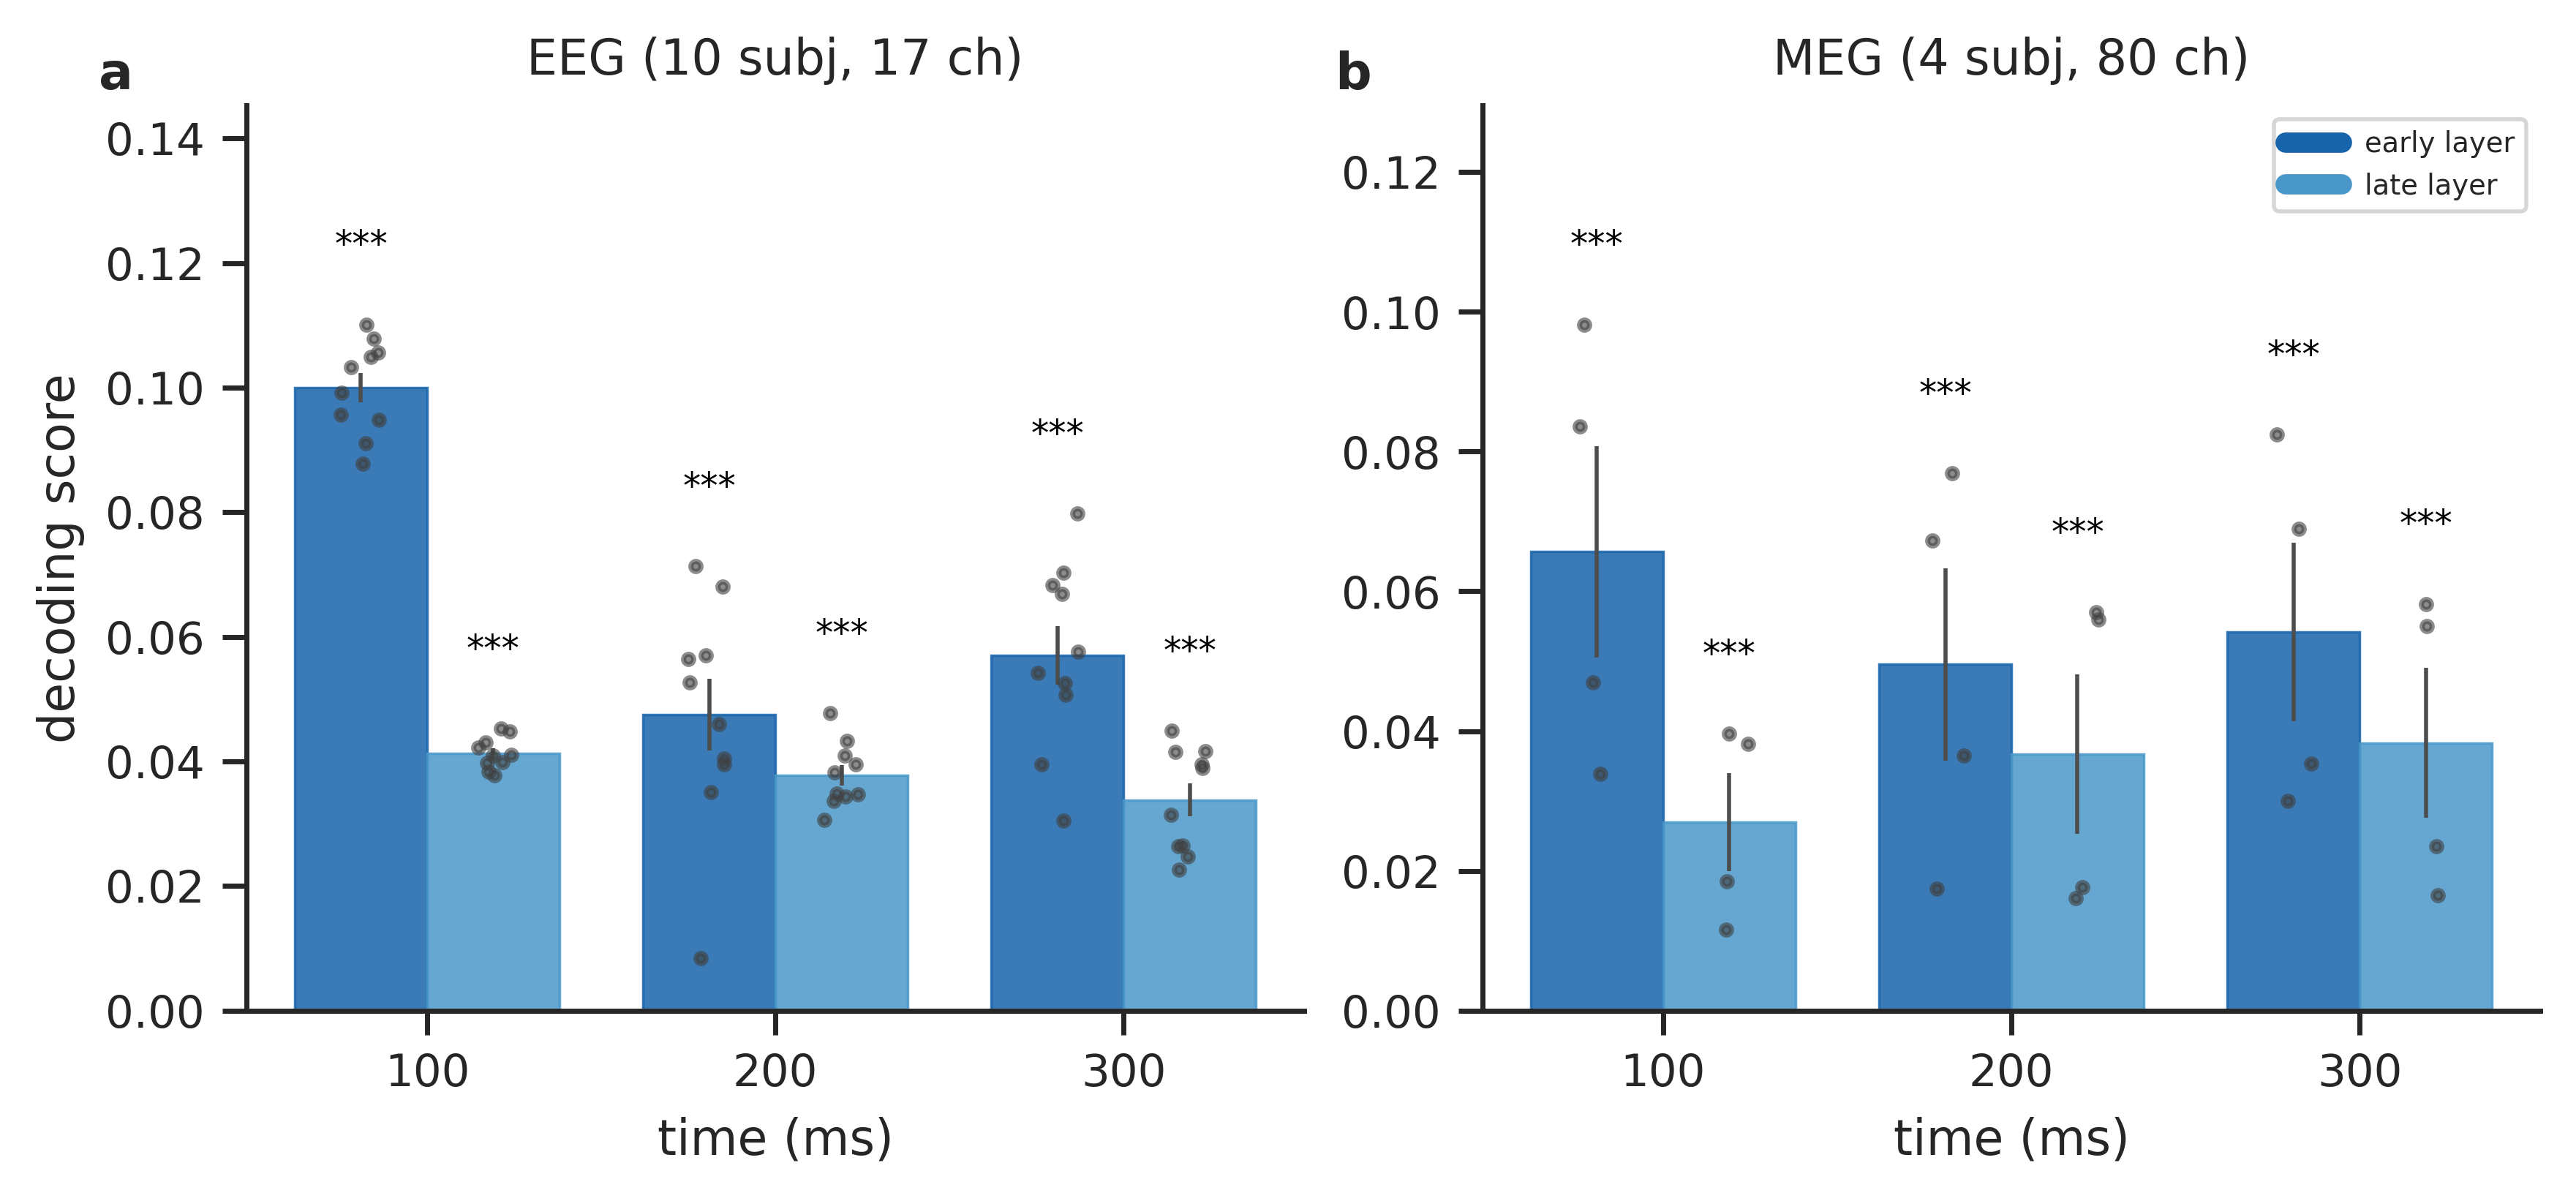

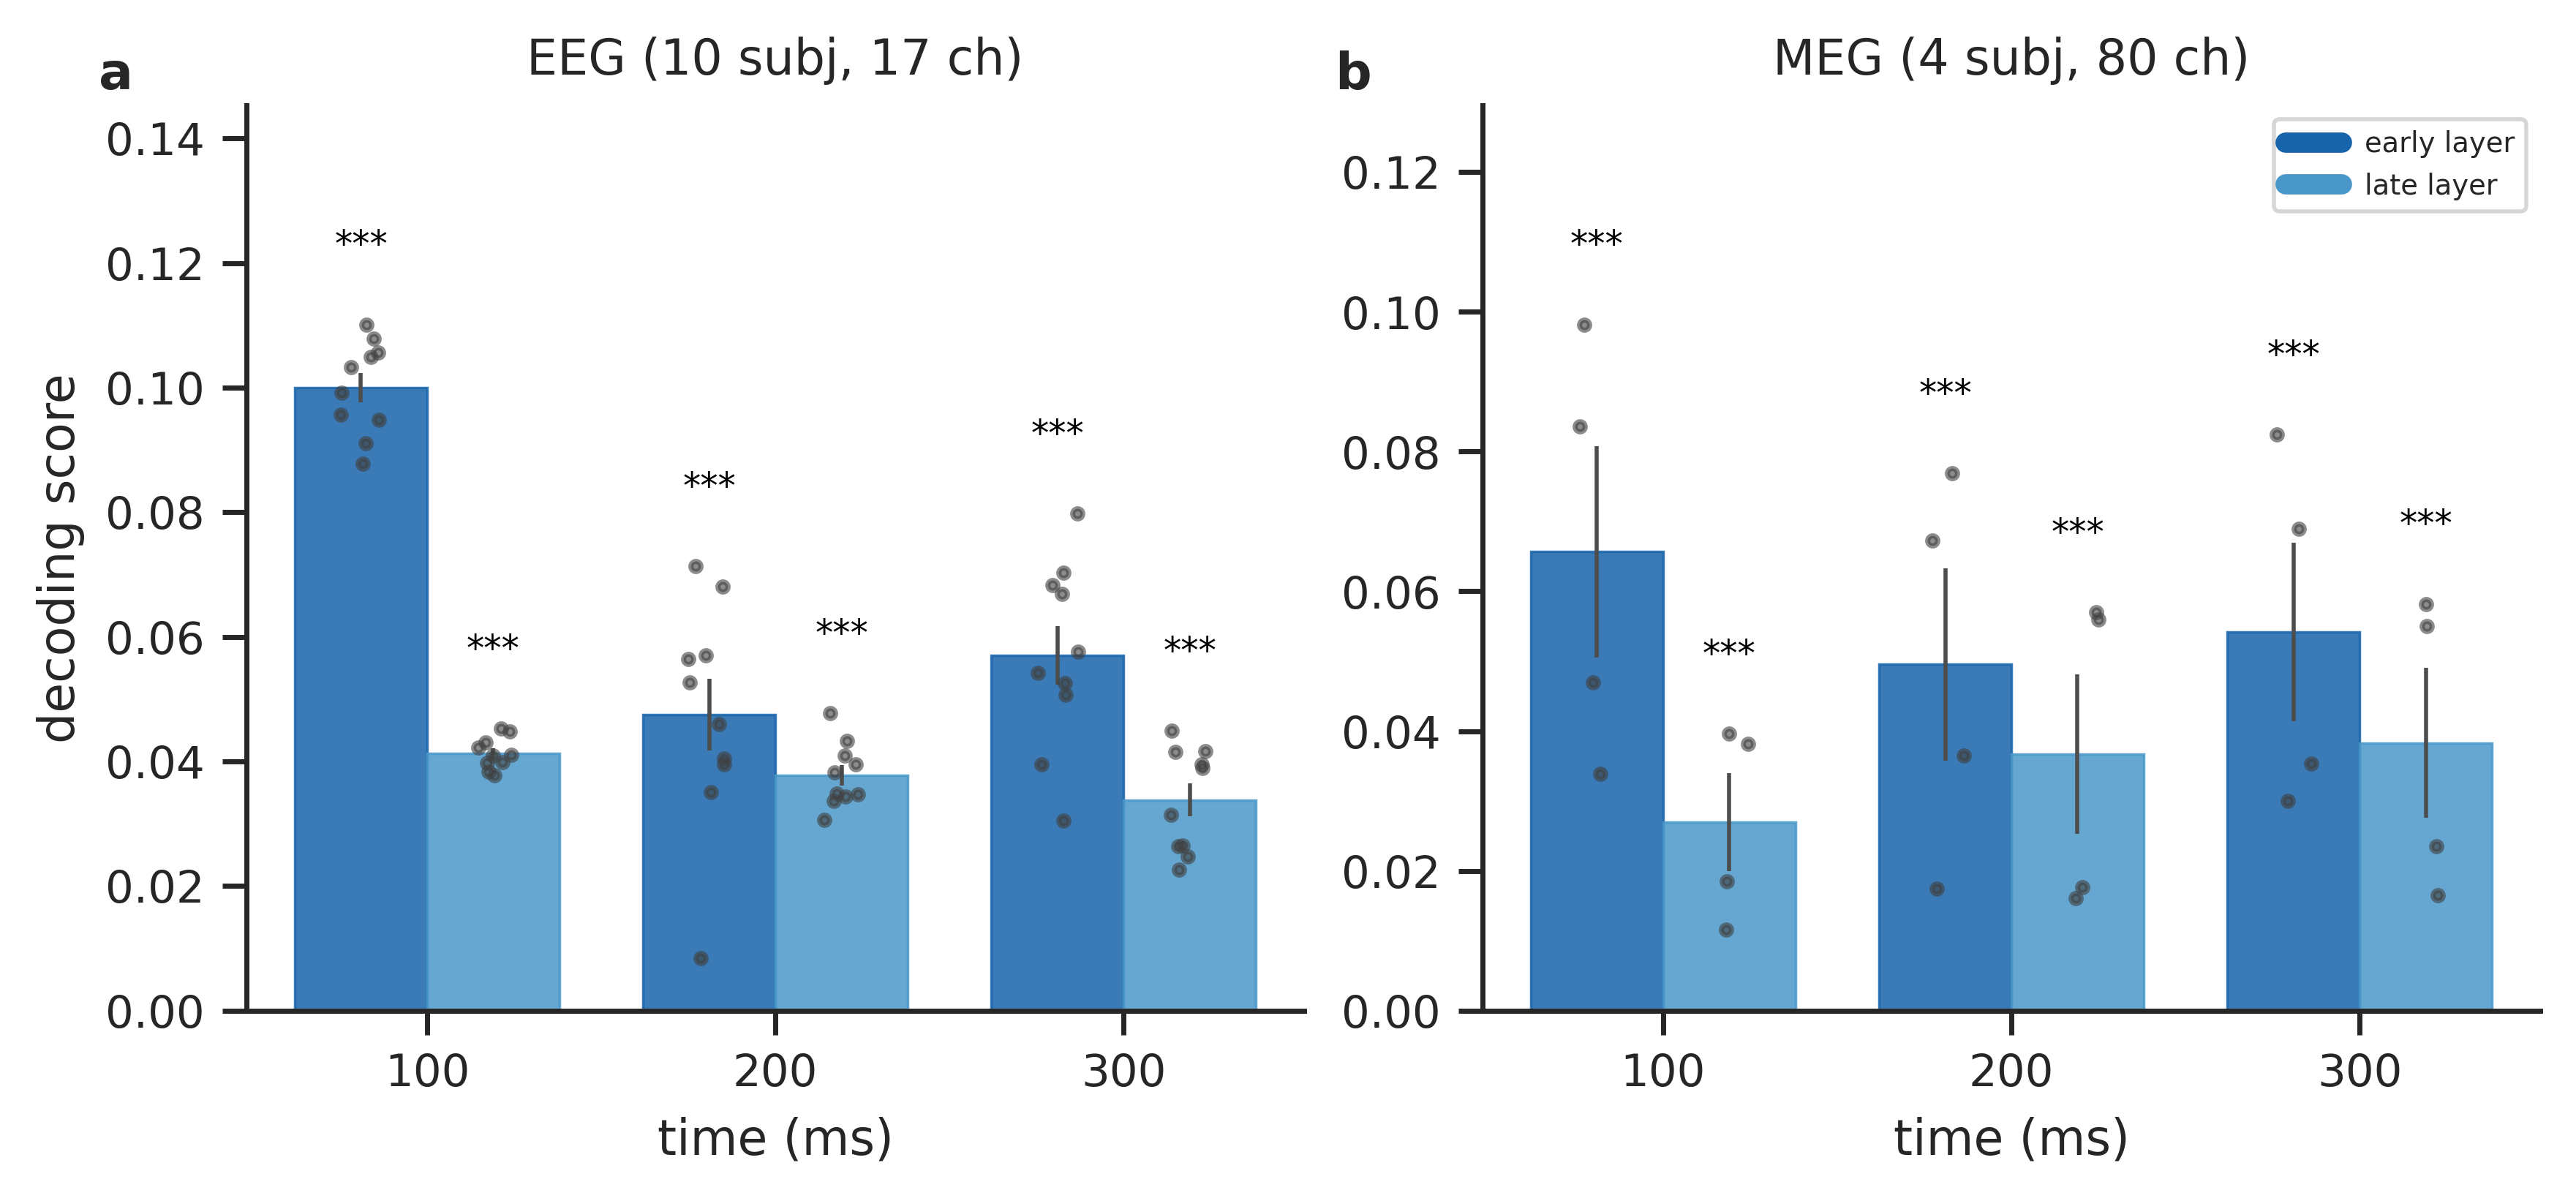

In [5]:
from matplotlib.transforms import Bbox

# manuscript figure standard: 176 mm wide, 600 dpi, 10 pt bold panel letters
WIDTH_MM = 176.0
width_inches = WIDTH_MM / 25.4
height_inches = width_inches / 3.5 * 1.6

BAR_TIMES = NULL_TARGET_TIMES  # [0.1, 0.2, 0.3]
BAR_FEATURES = ["early", "late"]
PANEL_TITLES = {"EEG": "EEG (10 subj, 17 ch)", "MEG": "MEG (4 subj, 80 ch)"}
PANEL_LETTERS = ["a", "b"]

OUT_PNG = Path("../../artifacts/figures/revision_r2/sfig_5.png")
OUT_PNG.parent.mkdir(parents=True, exist_ok=True)


def _pval_eeg(feature, tgt):
    # nearest residual-variant key in the EEG two-variant PVALS
    keys = [k for k in PVALS if k[0] == feature and k[1] == "residual"]
    return PVALS[min(keys, key=lambda k: abs(k[2] - tgt))]


def _pval_meg(feature, tgt):
    keys = [k for k in PVALS_MEG if k[0] == feature]
    return PVALS_MEG[min(keys, key=lambda k: abs(k[1] - tgt))]


PVAL_FN = {"EEG": _pval_eeg, "MEG": _pval_meg}


def _p_to_stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def _per_subj_at(df, tgt):
    # per-subject score (mean over neuroid) at the nearest cached time to tgt
    all_t = np.sort(df.time.unique())
    tt = all_t[np.argmin(np.abs(all_t - tgt))]
    return df[df.time == tt].groupby("subject").score.mean().values


plt.close("all")
fig, axs = plt.subplots(
    nrows=1, ncols=2, figsize=(width_inches, height_inches), sharey=False, layout="constrained"
)
xf = np.arange(len(BAR_TIMES))
w = 0.38
_jit = np.random.default_rng(0)

for ax, letter, (name, dataset, ldk) in zip(axs, PANEL_LETTERS, PANELS):
    res = load_feats(RES_STR, dataset, ldk)
    panel_top = 0.0
    for fi, key in enumerate(BAR_FEATURES):
        c = FCOLORS[key]
        for ti, tgt in enumerate(BAR_TIMES):
            vals = _per_subj_at(res[key], tgt)
            sem = vals.std(ddof=1) / np.sqrt(len(vals))
            panel_top = max(panel_top, vals.mean() + sem, vals.max())
            x0 = xf[ti] + (fi - 0.5) * w
            ax.bar(x0, vals.mean(), width=w, color=c, alpha=0.85, edgecolor=c, linewidth=0.5,
                   yerr=sem, error_kw=dict(lw=0.8, ecolor="0.3"))
            ax.plot(x0 + _jit.uniform(-0.06, 0.06, len(vals)), vals, "o", ms=2, color="0.25", alpha=0.6)
            stars = _p_to_stars(PVAL_FN[name](key, tgt))
            if stars:
                # clear the individual points too, not just the bar+SEM: a subject can sit
                # above the error bar and the star then lands on top of that point
                ax.annotate(stars, (x0, max(vals.mean() + sem, vals.max())),
                            textcoords="offset points",
                            xytext=(0, 12), ha="center", va="bottom", fontsize=7, color="k")
    ax.set_ylim(0, panel_top * 1.32)
    ax.set_xticks(xf)
    ax.set_xticklabels([f"{t * 1000:g}" for t in BAR_TIMES])
    ax.set_title(PANEL_TITLES[name])
    ax.set_xlabel("time (ms)")
    ax.axhline(0, color="k", lw=0.5)
    ax.text(-0.14, 1.06, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="top", ha="left")
    del res
    gc.collect()

axs[0].set_ylabel("decoding score")

legend_handles = [
    mlines.Line2D([], [], color=FCOLORS["early"], lw=4, label="early layer"),
    mlines.Line2D([], [], color=FCOLORS["late"], lw=4, label="late layer"),
]
axs[1].legend(handles=legend_handles, loc="upper right", fontsize="xx-small")
sns.despine(fig=fig)

# exact-width save: 'tight' expands past the canvas, so pin the Bbox to the figure size
fig.savefig(OUT_PNG, dpi=600, bbox_inches=Bbox([[0, 0], fig.get_size_inches()]))
print(f"wrote {OUT_PNG}")
fig

In [6]:
# verify the rendered width is exactly 176.0 mm
from PIL import Image

with Image.open(OUT_PNG) as im:
    dpi = im.info.get("dpi", (600, 600))[0]
    print(f"{im.size} px @ {dpi:.0f} dpi -> {im.size[0] / dpi * 25.4:.1f} x {im.size[1] / dpi * 25.4:.1f} mm")

(4157, 1900) px @ 600 dpi -> 176.0 x 80.4 mm
